# Medical Insurance Cost Prediction

## Problem Statement
The goal of this project is to build a machine learning model that predicts medical insurance charges based on demographic and health-related features such as age, BMI, smoking status, and region.

## Objective
To compare multiple regression models and select the best-performing model based on evaluation metrics.

## Dataset Description

The dataset contains 1338 records and 7 features:

- age: Age of the individual
- sex: Gender
- bmi: Body Mass Index
- children: Number of dependents
- smoker: Smoking status
- region: Residential region
- charges: Medical insurance cost (Target variable)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("insurance.csv")

# Display first 5 rows
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [ ]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [ ]:
df.isnull().sum()

,0
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0


In [ ]:
df["charges"].describe()

,charges
count,1338.000000
mean,13270.422265
std,12110.011237
min,1121.873900
25%,4740.287150
50%,9382.033000
75%,16639.912515
max,63770.428010


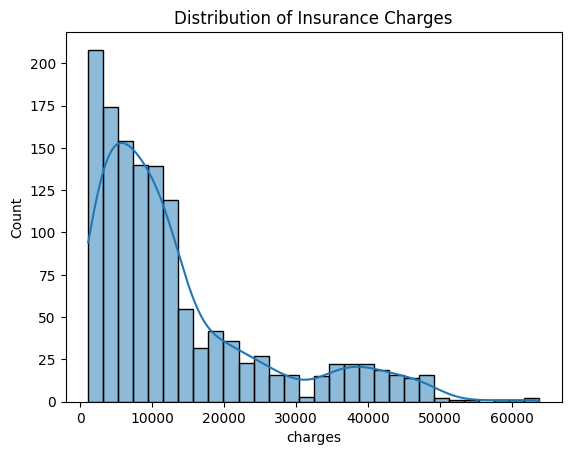

In [ ]:
sns.histplot(df["charges"], kde=True)
plt.title("Distribution of Insurance Charges")
plt.show()

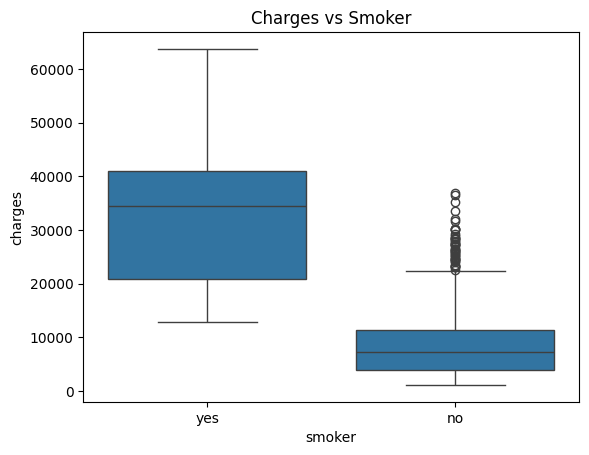

In [ ]:
sns.boxplot(x="smoker", y="charges", data=df)
plt.title("Charges vs Smoker")
plt.show()

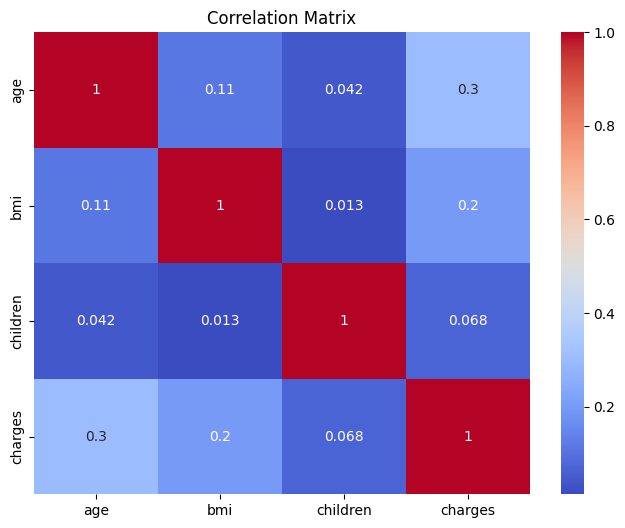

In [ ]:
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

## Exploratory Data Analysis (EDA)

- The distribution of insurance charges is right-skewed.
- Smoking status shows a strong impact on insurance costs.
- Correlation analysis indicates that smoker status and age are key predictive features.

In [ ]:
df_encoded = pd.get_dummies(df, drop_first=True)
df_encoded.head()

,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,False,True,False,False,True
1,18,33.770,1,1725.55230,True,False,False,True,False
2,28,33.000,3,4449.46200,True,False,False,True,False
3,33,22.705,0,21984.47061,True,False,True,False,False
4,32,28.880,0,3866.85520,True,False,True,False,False


In [ ]:
df_encoded.corr()["charges"].sort_values(ascending=False)

,charges
charges,1.000000
smoker_yes,0.787251
age,0.299008
bmi,0.198341
region_southeast,0.073982
children,0.067998
sex_male,0.057292
region_northwest,-0.039905
region_southwest,-0.043210


In [ ]:
X = df_encoded.drop("charges", axis=1)
y = df_encoded["charges"]

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

# Create model
lr = LinearRegression()

# Train model
lr.fit(X_train, y_train)

# Predict
y_pred = lr.predict(X_test)

# Evaluate
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("R2 Score:", r2)
print("RMSE:", rmse)

R2 Score: 0.7835929767120722
RMSE: 5796.284659276274


In [ ]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(random_state=42)

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

r2_rf = r2_score(y_test, y_pred_rf)
mse_rf = mean_squared_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mse_rf)
print("Random Forest R2:", r2_rf)
print("Random Forest RMSE:", rmse_rf)

Random Forest R2: 0.8656055394920775
Random Forest RMSE: 4567.775116331386


In [ ]:
import pandas as pd

results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "R2 Score": [r2, r2_rf],
    "RMSE": [rmse, rmse_rf]
})

results

,Model,R2 Score,RMSE
0,Linear Regression,0.783593,5796.284659
1,Random Forest,0.865606,4567.775116


## Model Comparison

Linear Regression:
- R²: 0.78
- RMSE: ~5796

Random Forest:
- R²: 0.86
- RMSE: ~4567

Random Forest performed better as it captured non-linear relationships in the dataset.

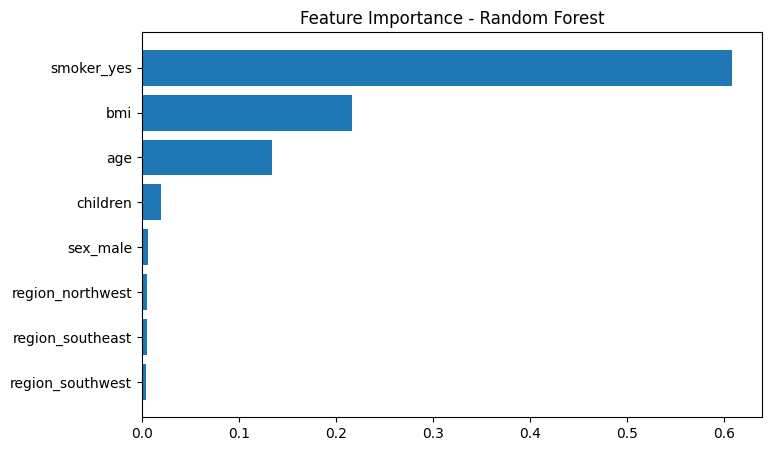

,Feature,Importance
4,smoker_yes,0.608618
1,bmi,0.216506
0,age,0.134232
2,children,0.019413
3,sex_male,0.006379
5,region_northwest,0.005587
6,region_southeast,0.005314
7,region_southwest,0.003950


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Get feature importances
importances = rf.feature_importances_

# Convert to DataFrame
feature_importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importances
})

# Sort
feature_importance_df = feature_importance_df.sort_values(by="Importance", ascending=False)

# Plot
plt.figure(figsize=(8,5))
plt.barh(feature_importance_df["Feature"], feature_importance_df["Importance"])
plt.gca().invert_yaxis()
plt.title("Feature Importance - Random Forest")
plt.show()

feature_importance_df

In [ ]:
import pickle

with open("insurance_model.pkl", "wb") as f:
    pickle.dump(rf, f)

## Conclusion

Random Forest was selected as the final model due to higher R² and lower RMSE.

Smoking status was identified as the most important feature contributing to insurance costs.

The model demonstrates strong predictive performance and can be further improved through hyperparameter tuning or advanced ensemble methods.

In [ ]:
print("Final Model Selected: Random Forest")
print("Final R2 Score:", r2_rf)
print("Final RMSE:", rmse_rf)

Final Model Selected: Random Forest
Final R2 Score: 0.8656055394920775
Final RMSE: 4567.775116331386


In [ ]:
def predict_insurance_cost(age, sex, bmi, children, smoker, region):
    import pandas as pd

    # Create input dataframe
    input_data = pd.DataFrame({
        "age": [age],
        "bmi": [bmi],
        "children": [children],
        "sex_male": [1 if sex == "male" else 0],
        "smoker_yes": [1 if smoker == "yes" else 0],
        "region_northwest": [1 if region == "northwest" else 0],
        "region_southeast": [1 if region == "southeast" else 0],
        "region_southwest": [1 if region == "southwest" else 0]
    })

    # Predict using trained pipeline
    prediction = pipeline.predict(input_data)

    return prediction[0]

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", RandomForestRegressor(random_state=42))
])

pipeline.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('model', RandomForestRegressor(random_state=42))])

In [ ]:
cost = predict_insurance_cost(
    age=30,
    sex="male",
    bmi=28.5,
    children=1,
    smoker="no",
    region="northwest"
)

print("Predicted Insurance Cost:", cost)

Predicted Insurance Cost: 16550.673341599988


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
